# Stock Triple-Barrier Classification · 04 Modeling

# Aim, Objective, and Motivation
- **Aim:** <u>find out</u> how well the triple-barrier outcome can be predicted, and whether sequence models
  (SimpleRNN, LSTM, GRU — the models of my first version) beat simpler ones.
- **Objective:** compare a prior baseline, logistic regression, LightGBM and three recurrent networks on the **validation** period
  (2022–2023), with uniqueness sample weights, and show how much purging changes cross-validation scores.
- **Motivation:** for a hard, noisy target the important question is not "which model is best" but "is anything better than guessing".

# Outlines
1. Load dataset
2. Metrics
3. Scaling & sample weights
4. Baselines: prior & logistic regression
5. LightGBM
6. Purged vs naive cross-validation
7. Sequences for recurrent networks
8. SimpleRNN, LSTM, GRU
9. Benchmark & save predictions
10. Summary

<!-- objective -->
## Objective

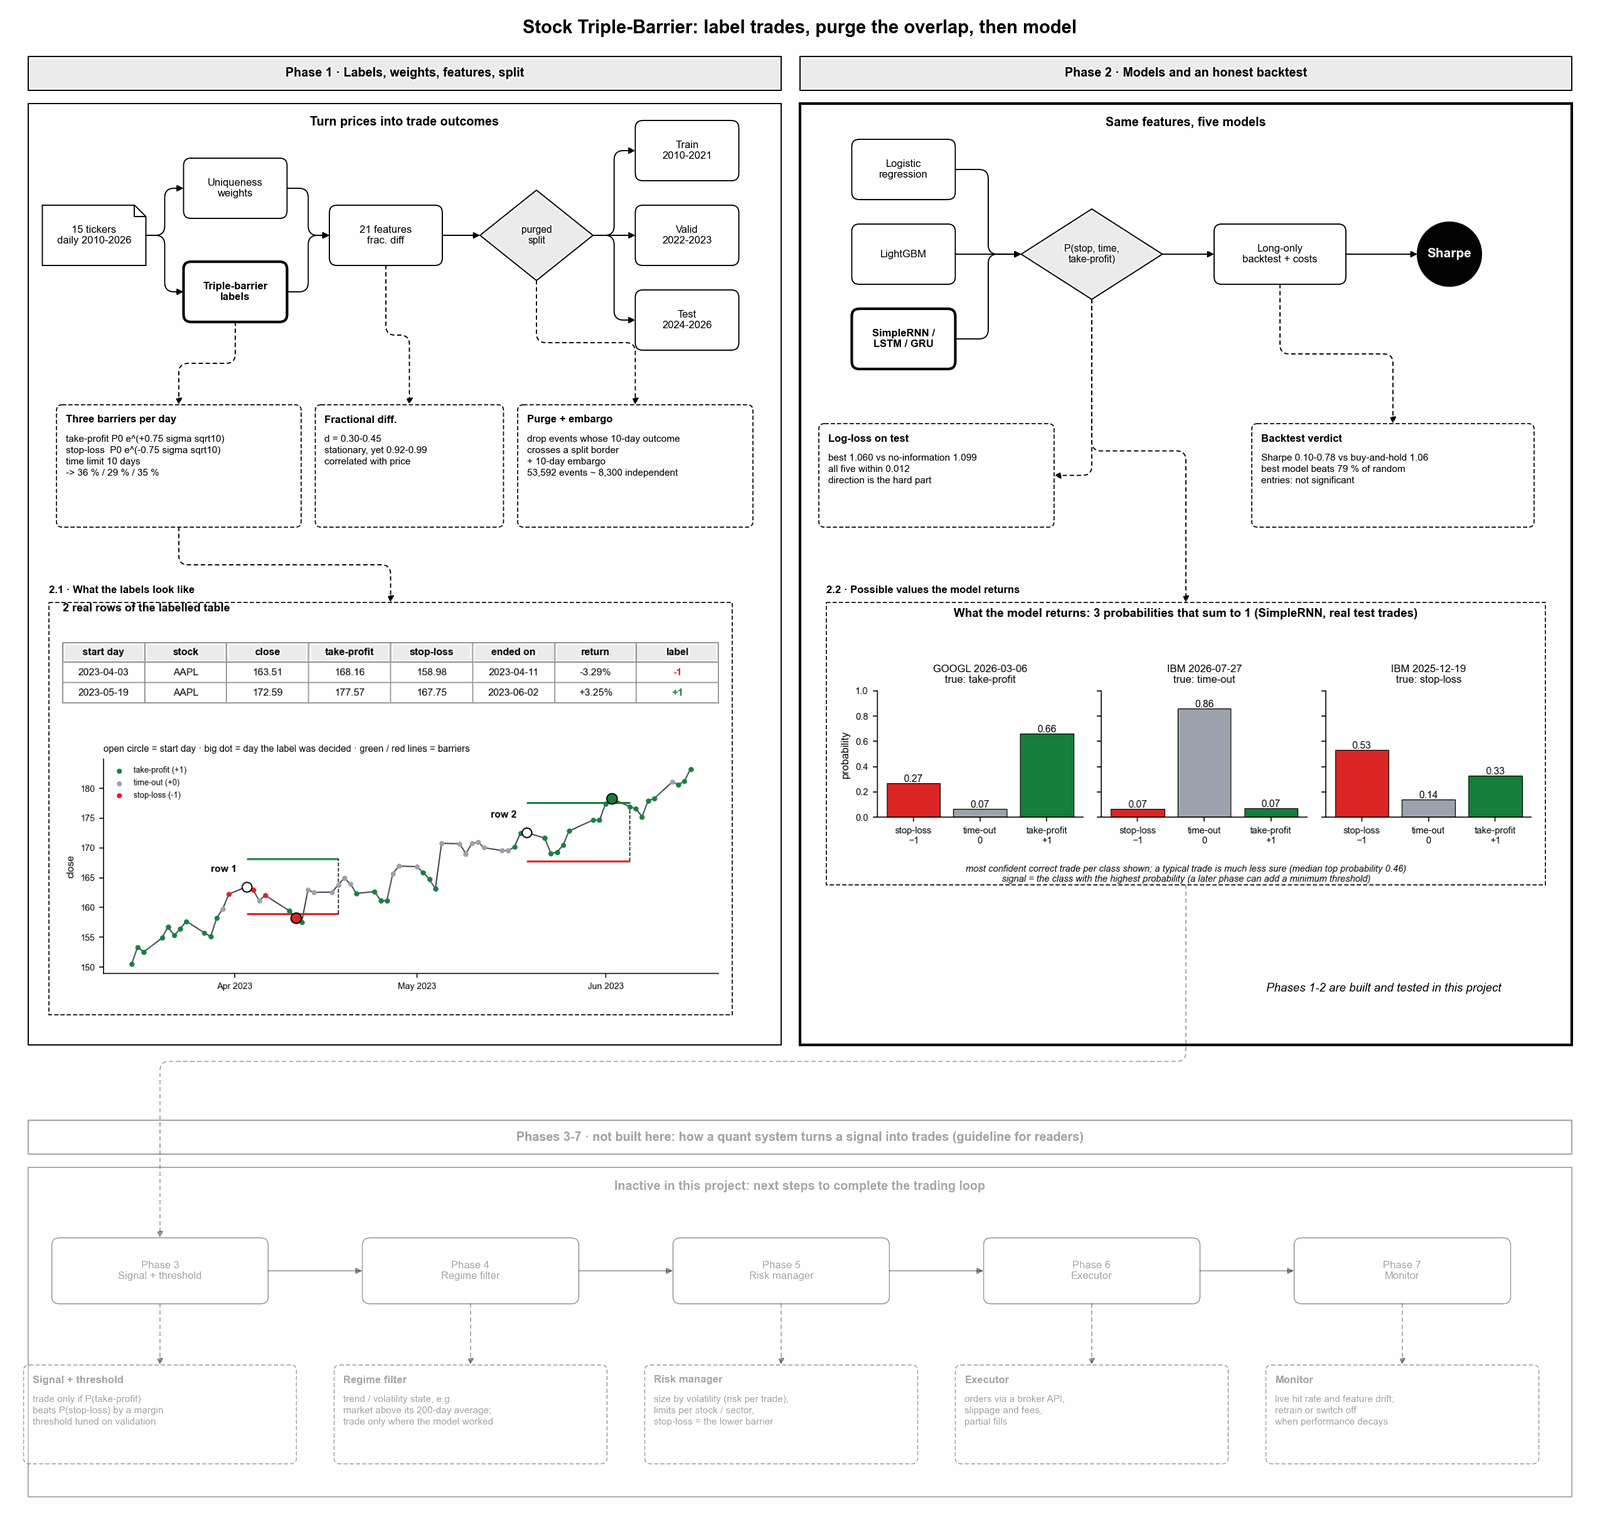

- **Problem** → most "stock prediction" notebooks predict tomorrow's price and report R² ≈ 0.99, yet copying yesterday's price scores the same: it looks smart and tells a trader nothing
- **Why this repo** → ask the question a trader actually has, *"if I buy today, do I hit my take-profit, my stop-loss, or run out of time?"*, and test it without leaking the future
- **Real-world use** → a sanity check before trusting any trading signal: label trades by outcome, purge overlapping samples, and compare against buy-and-hold and random entries

In [1]:
# ---------------------------------------------------------------- Imports
import os
os.environ["KERAS_BACKEND"] = "torch"          # Keras 3 on PyTorch -> uses the GPU on Windows

import sys
import json
import time
import warnings
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import keras
import lightgbm as lgb
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

from src.config import CLASSES, LABEL_COLORS, MODELS_DIR, PRICE_COLOR, RANDOM_STATE, REPORTS_DIR
from src.data import load_processed, save_processed
from src.evaluate import LABELS, PurgedKFold, make_sequences, score
from src.features import FEATURES
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
SEED = RANDOM_STATE
LOOKBACK = 30                      # days of features in each sequence
EPOCHS = 60
BATCH_SIZE = 256
PATIENCE = 8                       # early-stopping patience (epochs)
UNITS = 64                         # recurrent units
DROPOUT = 0.3
LEARNING_RATE = 1e-3
CLIP = 5.0                         # clip standardised features to +-5 to tame extreme days
CV_FOLDS = 5
EMBARGO_DAYS = 10
TO_CLASS = {-1: 0, 0: 1, 1: 2}     # label -> class index (column order of every probability matrix)
LGB_PARAMS = dict(objective="multiclass", n_estimators=2000, learning_rate=0.02, num_leaves=15, min_child_samples=200,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)

set_style()
keras.utils.set_random_seed(SEED)
DEVICE = "GPU " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

# [1/10] Load dataset
> **Objective:** <u>load</u> the features and labels from notebook 03; purged events are not used.

In [2]:
data = load_processed("dataset").sort_values(["ticker", "date"]).reset_index(drop=True)
data["y"] = data["label"].map(TO_CLASS)
is_train, is_valid, is_test = (data.split == s for s in ("train", "valid", "test"))

In [3]:
print(f"Keras {keras.__version__} on {keras.backend.backend()} ({DEVICE})")
data.split.value_counts()

Keras 3.12.1 on torch (GPU NVIDIA GeForce RTX 5060)


split
train     34024
test       9926
valid      6892
purged      244
Name: count, dtype: int64

# [2/10] Metrics
> **Question:** how do we judge a 3-class model on a noisy financial target?
>
> - **Macro-F1** $= \frac{1}{3}\sum_{c} F1_c$ — every class counts equally; a model predicting one class scores at most ~0.17.
> - **Balanced accuracy** $= \frac{1}{3}\sum_c \text{recall}_c$ — 0.333 is random guessing.
> - **Log-loss** $= -\frac{1}{n}\sum_i \sum_c y_{ic} \ln \hat p_{ic}$ (uniqueness-weighted) — rewards honest probabilities;
>   the **prior** baseline (always predict the training class frequencies) sets the bar.
> - **Take-profit precision** — of the days predicted "take-profit", how many really were? This is what a long-only strategy needs.

# [3/10] Scaling & sample weights
> - **Standardisation** $z = \frac{x - \mu_{train}}{\sigma_{train}}$, fitted on **training rows only**, then clipped to $\pm 5$.
> - **Sample weight** = event uniqueness (notebook 02), rescaled to mean 1 in each split, so overlapping events share weight.

In [4]:
scaler = StandardScaler().fit(data.loc[is_train, FEATURES])
data[FEATURES] = np.clip(scaler.transform(data[FEATURES]), -CLIP, CLIP).astype(np.float32)
data["w"] = data["uniqueness"] / data.groupby("split")["uniqueness"].transform("mean")

X = {s: data.loc[m, FEATURES] for s, m in [("train", is_train), ("valid", is_valid), ("test", is_test)]}
y = {s: data.loc[m, "y"].to_numpy() for s, m in [("train", is_train), ("valid", is_valid), ("test", is_test)]}
w = {s: data.loc[m, "w"].to_numpy() for s, m in [("train", is_train), ("valid", is_valid), ("test", is_test)]}
y_label = {s: np.array(LABELS)[v] for s, v in y.items()}

In [5]:
pd.DataFrame({s: [len(y[s]), w[s].mean()] for s in y}, index=["rows", "mean weight"]).round(3)

,train,valid,test
rows,34024.0,6892.0,9926.0
mean weight,1.0,1.0,1.0


Helper: every model's validation and test probabilities are stored for the benchmark and for notebook 05.

In [6]:
results, probas = [], {"valid": {}, "test": {}}


def record(name, p_valid, p_test):
    probas["valid"][name], probas["test"][name] = p_valid, p_test
    results.append(score(y_label["valid"], p_valid, name, weights=w["valid"]))


def results_table():
    return pd.DataFrame(results).drop_duplicates("model", keep="last").set_index("model").round(4)

# [4/10] Baselines: prior & logistic regression
> - **Prior:** predict the training class frequencies for every day (no information at all).
> - **Multinomial logistic regression:** $P(y = c \mid x) = \frac{e^{w_c^\top x}}{\sum_k e^{w_k^\top x}}$ — a linear model.

In [7]:
prior = np.bincount(y["train"], weights=w["train"], minlength=3) / w["train"].sum()
record("Prior (class frequencies)", np.tile(prior, (len(y["valid"]), 1)), np.tile(prior, (len(y["test"]), 1)))

logreg = LogisticRegression(max_iter=2000, C=0.1).fit(X["train"], y["train"], sample_weight=w["train"])
record("Logistic Regression", logreg.predict_proba(X["valid"]), logreg.predict_proba(X["test"]))

In [8]:
results_table()

,macro_f1,balanced_acc,log_loss,tp_precision,tp_recall
model,,,,,
Prior (class frequencies),0.1726,0.3333,1.1002,0.3492,1.0000
Logistic Regression,0.3326,0.4000,1.0896,0.4013,0.6361


# [5/10] LightGBM
> Gradient-boosted trees on the same 21 features of the event day (no sequence). Early stopping on the validation log-loss
> chooses the number of trees.

In [9]:
lgbm = lgb.LGBMClassifier(**LGB_PARAMS)
lgbm.fit(X["train"], y["train"], sample_weight=w["train"],
         eval_set=[(X["valid"], y["valid"])], eval_sample_weight=[w["valid"]],
         callbacks=[lgb.early_stopping(100, verbose=False)])
record("LightGBM", lgbm.predict_proba(X["valid"]), lgbm.predict_proba(X["test"]))
joblib.dump(lgbm, MODELS_DIR / "lightgbm.joblib")

['D:\\my-repo\\projects\\deep-learning\\dl-multiclassification-stock-triple-barrier-rnn-lstm\\models\\lightgbm.joblib']

In [10]:
print(f"best iteration: {lgbm.best_iteration_}")
results_table()

best iteration: 65


,macro_f1,balanced_acc,log_loss,tp_precision,tp_recall
model,,,,,
Prior (class frequencies),0.1726,0.3333,1.1002,0.3492,1.0000
Logistic Regression,0.3326,0.4000,1.0896,0.4013,0.6361
LightGBM,0.3333,0.3982,1.0841,0.3982,0.6739


# [6/10] Purged vs naive cross-validation
> **Question:** how much does ordinary K-fold cross-validation overstate performance when labels overlap in time?
>
> - **Naive K-fold (shuffled):** neighbouring days — which share most of their future prices — land in train and test folds.
> - **Purged K-fold with embargo:** folds are contiguous blocks of time; training events overlapping the test block are removed
>   (purging) and so are events starting within 10 days after it (embargo).

In [11]:
cv_data = data.loc[is_train].reset_index(drop=True)
cv_model = dict(LGB_PARAMS, n_estimators=300)
cv_rows = []
splitters = {"naive shuffled K-fold": KFold(CV_FOLDS, shuffle=True, random_state=SEED).split(cv_data),
             "purged K-fold + embargo": PurgedKFold(CV_FOLDS, EMBARGO_DAYS).split(cv_data["date"], cv_data["t1"])}
for cv_name, folds in splitters.items():
    for k, (tr, te) in enumerate(folds):
        m = lgb.LGBMClassifier(**cv_model).fit(cv_data.loc[tr, FEATURES], cv_data.loc[tr, "y"],
                                               sample_weight=cv_data.loc[tr, "w"])
        s = score(np.array(LABELS)[cv_data.loc[te, "y"]], m.predict_proba(cv_data.loc[te, FEATURES]), cv_name,
                  weights=cv_data.loc[te, "w"])
        cv_rows.append({**s, "fold": k, "train_rows": len(tr)})
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby("model")[["macro_f1", "balanced_acc", "log_loss", "train_rows"]].mean()

In [12]:
cv_summary.round(4)

,macro_f1,balanced_acc,log_loss,train_rows
model,,,,
naive shuffled K-fold,0.4722,0.4836,0.9903,27219.2
purged K-fold + embargo,0.3940,0.4133,1.0682,27076.2


**Answer:** shuffled K-fold reports macro-F1 **0.472** and log-loss 0.990; purged K-fold with embargo reports **0.394** and 1.068.
The gap comes from overlapping neighbours of each test day sitting in the training folds. On the truly unseen validation period
LightGBM reaches 0.333 macro-F1 and log-loss 1.084, so purged CV is far closer to reality, though still somewhat optimistic
(the market regime also changes between periods). Shuffled K-fold should never be used for this kind of data.

# [7/10] Sequences for recurrent networks
> **Objective:** <u>give</u> each event the last 30 days of features of its stock: input shape $(n, 30, 21)$.
> Windows may reach back into an earlier split — that is past information, available at prediction time.

In [13]:
X_seq_all, row_idx = make_sequences(data, FEATURES, LOOKBACK)
pos = pd.Series(np.arange(len(row_idx)), index=row_idx)
seq = {}
for s, m in [("train", is_train), ("valid", is_valid), ("test", is_test)]:
    rows = data.index[m]
    keep = rows[np.isin(rows, row_idx)]
    seq[s] = (X_seq_all[pos[keep].to_numpy()], data.loc[keep, "y"].to_numpy(), data.loc[keep, "w"].to_numpy(), keep)

In [14]:
{s: v[0].shape for s, v in seq.items()}

{'train': (33618, 30, 21), 'valid': (6892, 30, 21), 'test': (9926, 30, 21)}

The sequence sets are slightly smaller (each stock's first 29 events have no full window), so for a fair comparison the
non-sequence models are also scored on exactly these rows in the benchmark.

# [8/10] SimpleRNN, LSTM, GRU
> All three use the same architecture: recurrent layer (64 units) → dropout 0.3 → dense 32 (ReLU) → softmax over 3 classes,
> trained with Adam on the uniqueness-weighted cross-entropy, early stopping on validation loss.
>
> - **SimpleRNN:** $h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$ — suffers from vanishing gradients on long sequences.
> - **LSTM:** gates $f_t, i_t, o_t = \sigma(\cdot)$ control a cell state $c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$, $h_t = o_t \odot \tanh(c_t)$.
> - **GRU:** update gate $z_t$ and reset gate $r_t$; $h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde h_t$ — fewer parameters than LSTM.

**Inside the recurrent models** → the same input window and head for all three; only the recurrent cell changes

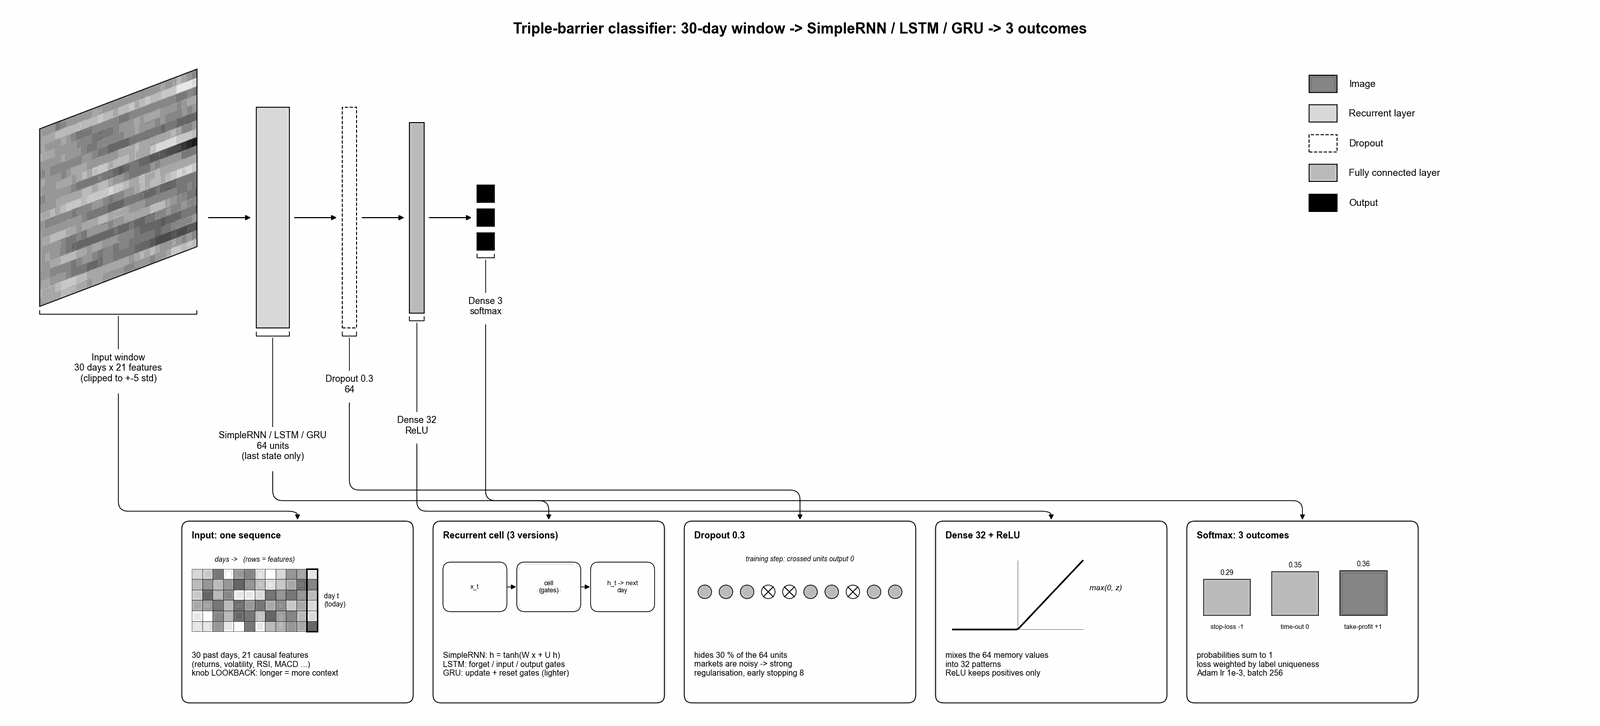

In [15]:
LAYERS = {"SimpleRNN": keras.layers.SimpleRNN, "LSTM": keras.layers.LSTM, "GRU": keras.layers.GRU}
histories, fit_seconds = {}, {}
Xtr, ytr, wtr, _ = seq["train"]
Xva, yva, wva, _ = seq["valid"]
Xte = seq["test"][0]
for name, layer in LAYERS.items():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input((LOOKBACK, len(FEATURES))),
        layer(UNITS),
        keras.layers.Dropout(DROPOUT),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(3, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss="sparse_categorical_crossentropy",
                  weighted_metrics=["accuracy"])
    start = time.time()
    hist = model.fit(Xtr, ytr, sample_weight=wtr, validation_data=(Xva, yva, wva), epochs=EPOCHS, batch_size=BATCH_SIZE,
                     callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)], verbose=0)
    fit_seconds[name] = time.time() - start
    histories[name] = pd.DataFrame(hist.history)
    model.save(MODELS_DIR / f"{name.lower()}.keras")
    record(name, model.predict(Xva, verbose=0), model.predict(Xte, verbose=0))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h["loss"], color=PRICE_COLOR, label="train")
    ax.plot(h["val_loss"], color="#dc2626", label="validation")
    ax.axvline(h["val_loss"].idxmin(), color="black", ls=":", lw=1)
    ax.set(title=f"{name}: loss per epoch", xlabel="epoch")
    ax.legend()
savefig(fig, "04_training_curves")
plt.close(fig)

In [16]:
pd.DataFrame({"epochs_run": {k: len(h) for k, h in histories.items()},
              "best_epoch": {k: int(h["val_loss"].idxmin()) + 1 for k, h in histories.items()},
              "fit_seconds": fit_seconds}).round(1)

,epochs_run,best_epoch,fit_seconds
SimpleRNN,15,7,129.0
LSTM,12,4,161.1
GRU,12,4,178.1


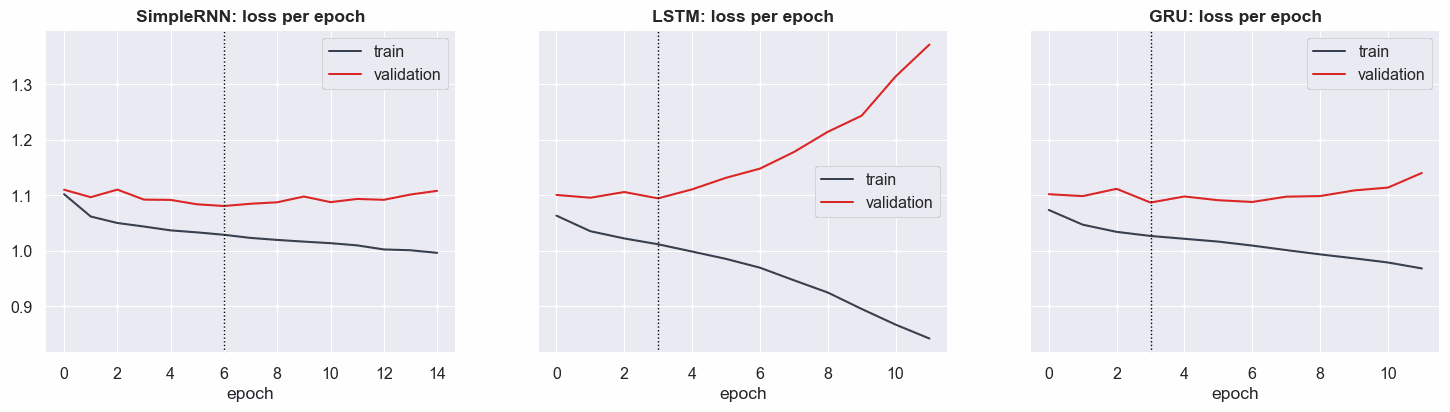

In [17]:
fig

**Answer:** validation loss is lowest at epoch 7 (SimpleRNN) and epoch 4 (LSTM, GRU), then rises while training loss keeps falling:
the networks start memorising noise almost immediately. Early stopping restores the best epoch; each network trains in 2–3 minutes
on the GPU.

# [9/10] Benchmark & save predictions
> **Objective:** <u>compare</u> all models on the **same** validation rows (those with a full 30-day window).

In [18]:
valid_rows = seq["valid"][3]
test_rows = seq["test"][3]
v_pos = pd.Series(np.arange(is_valid.sum()), index=data.index[is_valid])
t_pos = pd.Series(np.arange(is_test.sum()), index=data.index[is_test])
yv = np.array(LABELS)[data.loc[valid_rows, "y"]]
wv = data.loc[valid_rows, "w"].to_numpy()
bench = []
for name, p in probas["valid"].items():
    p_same = p if name in LAYERS else p[v_pos[valid_rows].to_numpy()]
    bench.append(score(yv, p_same, name, weights=wv))
benchmark = pd.DataFrame(bench).set_index("model").sort_values("log_loss")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
b = benchmark.sort_values("macro_f1")
axes[0].barh(b.index, b["macro_f1"], color=PRICE_COLOR)
axes[0].axvline(1 / 3, color="black", ls=":", lw=1)
axes[0].set(title="Validation macro-F1", xlim=(0, max(0.5, b["macro_f1"].max() * 1.15)))
b = benchmark.sort_values("log_loss", ascending=False)
axes[1].barh(b.index, b["log_loss"], color=["#dc2626" if i.startswith("Prior") else PRICE_COLOR for i in b.index])
axes[1].set(title="Validation log-loss (lower is better; red = prior baseline)",
            xlim=(b["log_loss"].min() * 0.97, b["log_loss"].max() * 1.02))
savefig(fig, "04_benchmark")
plt.close(fig)

# save validation + test probabilities of every model (same rows for all) for notebook 05
out = []
for split_name, rows, posmap in [("valid", valid_rows, v_pos), ("test", test_rows, t_pos)]:
    base = data.loc[rows, ["date", "ticker", "label", "t1", "ret", "uniqueness"]].reset_index(drop=True)
    for name, p in probas[split_name].items():
        p_same = p if name in LAYERS else p[posmap[rows].to_numpy()]
        for c, lab in enumerate(LABELS):
            base[f"{name}|p{lab:+d}"] = p_same[:, c]
    base["split"] = split_name
    out.append(base)
save_processed(pd.concat(out, ignore_index=True), "predictions")
benchmark.to_csv(REPORTS_DIR / "validation_benchmark.csv")
json.dump({"features": FEATURES, "lookback": LOOKBACK, "scaler_mean": scaler.mean_.tolist(),
           "scaler_scale": scaler.scale_.tolist(), "clip": CLIP}, open(REPORTS_DIR / "preprocessing.json", "w"), indent=2)

In [19]:
benchmark

,macro_f1,balanced_acc,log_loss,tp_precision,tp_recall
model,,,,,
SimpleRNN,0.360382,0.414166,1.080333,0.412533,0.642709
LightGBM,0.333299,0.398228,1.084103,0.398232,0.673868
GRU,0.363166,0.410496,1.086536,0.402621,0.651018
Logistic Regression,0.332567,0.400039,1.089597,0.401311,0.636061
LSTM,0.365495,0.381956,1.094095,0.380586,0.555463
Prior (class frequencies),0.172563,0.333333,1.100186,0.349246,1.000000


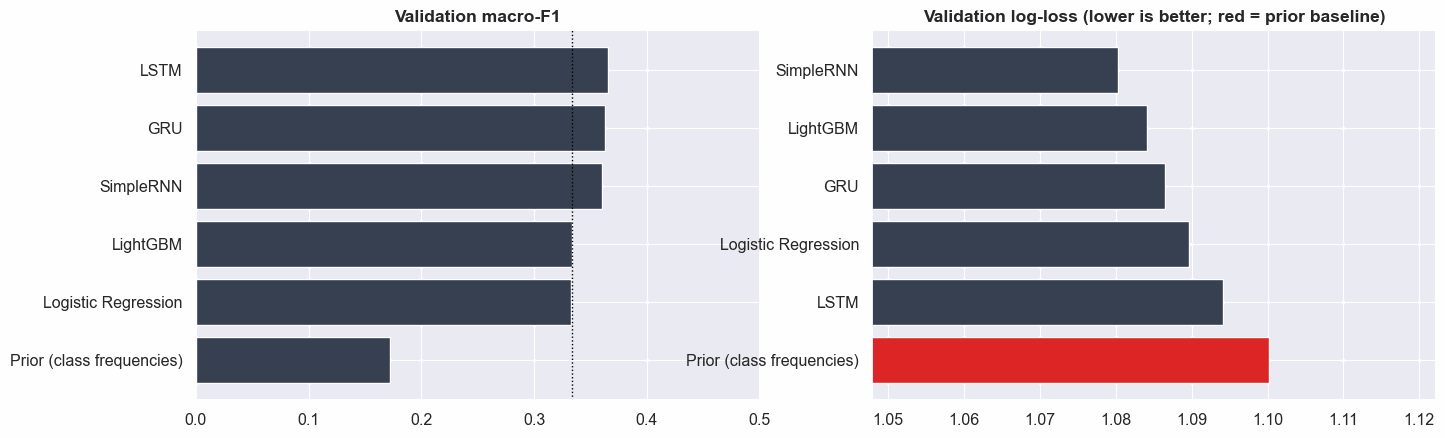

In [20]:
fig

**Answer:** every model beats the prior baseline, but only by a little.
- **SimpleRNN** has the best log-loss (1.080 vs 1.100 for the prior) and balanced accuracy (0.414 vs 0.333), with take-profit
  precision 0.41 against a base rate of 0.35.
- LightGBM (1.084) and GRU (1.087) follow; the LSTM is the weakest learned model on log-loss (1.094).
- The recurrent networks reach a higher macro-F1 (0.36–0.37 vs 0.33) partly because they predict stop-loss more often
  (SimpleRNN 5 %, GRU 7 %, LSTM 18 % of validation days vs 2–3 % for logistic regression and LightGBM). All models mostly
  predict take-profit (51–59 %) or time-out.

The differences between models are small compared with the gap to the prior, and come from a single two-year period.
Notebook 05 checks whether the edge survives on the test period and in a backtest with costs.

# [10/10] Summary
- Six models compared on the same validation rows, with uniqueness weights and a purged split.
- All learned models beat the prior baseline by a small margin; SimpleRNN is best on log-loss (1.080 vs 1.100).
- Purged cross-validation (macro-F1 0.394) is much more honest than shuffled K-fold (0.472).
- Validation and test probabilities of every model are saved to `data/processed/predictions.parquet` for notebook 05.